# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

> При выполнении и оформлении работы использовалась LLM Claude Opus 5.5 (Anthropic) в среде Claude Code: для помощи в построении графиков и дизайна приложения на Streamlit

In [21]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [23]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        X = self._add_intercept(X)
        N = X.shape[0]
        self.w = np.zeros(X.shape[1]) if self.w0 is None else np.array(self.w0, dtype=float)
        self.stopped_by_tolerance_ = False

        for _ in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X, y))

            if self.gd_type == 'full':
                grad = self.calc_gradient(X, y)
            else:
                idx = rng.choice(N, size=min(self.batch_size, N), replace=False)
                grad = self.calc_gradient(X[idx], y[idx])

            w_new = self.w - self.eta * grad
            step_norm = np.linalg.norm(w_new - self.w)
            self.w = w_new

            if step_norm < self.tolerance:
                self.stopped_by_tolerance_ = True
                break

        self.n_iter_ = len(self.loss_history)
        return self

    def _add_intercept(self, X):
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        X = self._add_intercept(np.asarray(X, dtype=float))
        p = self.sigmoid(X @ self.w)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        p = self.sigmoid(X @ self.w)
        return X.T @ (p - y) / X.shape[0]

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        p = np.clip(self.sigmoid(X @ self.w), 1e-15, 1 - 1e-15)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [24]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 2.28e-10


Теперь проверим работу класса на синтетических данных.

In [25]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

GD: итераций 1000, остановка по max_iter, последний loss = 0.5125
SGD: итераций 1000, остановка по max_iter, последний loss = 0.5129
объектов за итерацию: GD = 14000 , SGD = 32


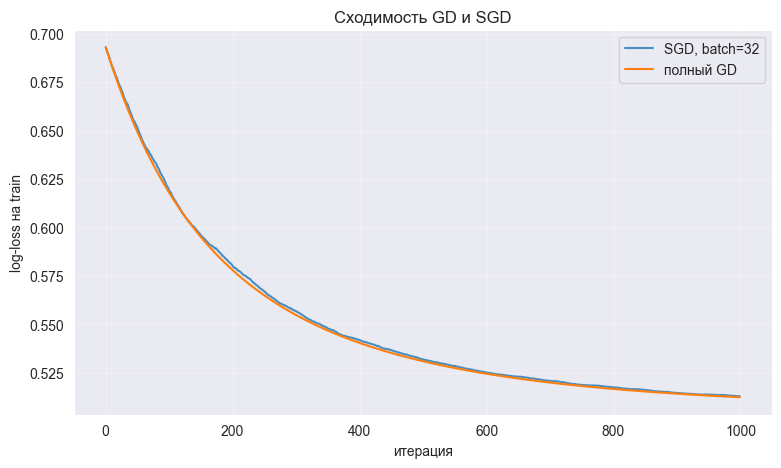

In [26]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)

for name, model in [('GD', gd), ('SGD', sgd)]:
    criterion = 'tolerance' if model.stopped_by_tolerance_ else 'max_iter'
    print(f'{name}: итераций {model.n_iter_}, остановка по {criterion}, '
          f'последний loss = {model.loss_history[-1]:.4f}')

print('объектов за итерацию: GD =', X_train.shape[0], ', SGD =', sgd.batch_size)

plt.figure(figsize=(9, 5))
plt.plot(sgd.loss_history, label='SGD, batch=32', alpha=0.8)
plt.plot(gd.loss_history, label='полный GD')
plt.xlabel('итерация')
plt.ylabel('log-loss на train')
plt.title('Сходимость GD и SGD')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Обе модели сделали по 1000 итераций и остановились по `max_iter`, до `tolerance` не дошла ни одна. У полного GD разность весов равна `eta * градиент`, поэтому при eta = 0.01 критерий сработал бы только при норме градиента меньше 0.01. За 1000 итераций спуск до этого не добрался: loss 0.5125, а минимум около 0.5058 (видно в 1.3).

Стохастическому спуску с постоянным шагом остановиться трудно, потому что градиент по батчу случайный и рядом с минимумом к нулю не стремится: разные батчи тянут веса в разные стороны. В точке минимума норма градиента по батчу из 32 объектов в среднем около 0.3, значит разность весов около 0.003, это примерно в 30 раз больше `tolerance`.

Графики почти совпадают, финальный loss 0.5125 у GD и 0.5129 у SGD. Кривая GD гладкая и монотонная, а у SGD немного неровная, причём loss может и подрасти между итерациями.

За одну итерацию GD просматривает все 14000 объектов, а SGD только 32. За весь спуск это 14 млн объектов против 32 тысяч (примерно 2.3 прохода по выборке), то есть SGD получил почти такой же loss примерно в 440 раз дешевле.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

eta=0.001: итераций 1000, финальный loss = 0.6181, минимальный loss = 0.6181
eta=0.01: итераций 1000, финальный loss = 0.5125, минимальный loss = 0.5125
eta=0.1: итераций 465, финальный loss = 0.5058, минимальный loss = 0.5058
eta=1: итераций 70, финальный loss = 0.5058, минимальный loss = 0.5058
eta=10: итераций 1000, финальный loss = 0.9458, минимальный loss = 0.6257


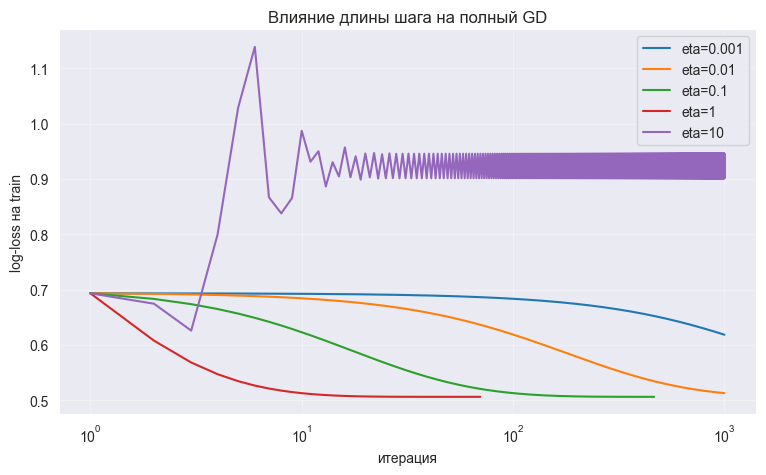

In [27]:
etas = [1e-3, 1e-2, 1e-1, 1, 10]
results_eta = {}

for eta in etas:
    model = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    results_eta[eta] = model
    print(f'eta={eta}: итераций {model.n_iter_}, финальный loss = {model.loss_history[-1]:.4f}, '
          f'минимальный loss = {min(model.loss_history):.4f}')

plt.figure(figsize=(9, 5))
for eta, model in results_eta.items():
    plt.plot(np.arange(1, model.n_iter_ + 1), model.loss_history, label=f'eta={eta}')
plt.xscale('log')
plt.xlabel('итерация')
plt.ylabel('log-loss на train')
plt.title('Влияние длины шага на полный GD')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- eta = 0.001: 1000 итераций, loss 0.6181. Шаг слишком маленький, спуск почти не сдвинулся и остановился по `max_iter`.
- eta = 0.01: 1000 итераций, loss 0.5125. Тоже не дошёл до минимума.
- eta = 0.1: 465 итераций, loss 0.5058, остановка по `tolerance`.
- eta = 1: 70 итераций, loss 0.5058. Самый быстрый вариант, loss такой же.
- eta = 10: 1000 итераций, финальный loss 0.9458. Спуск ведёт себя плохо.

Пока шаг не слишком большой, увеличение шага только ускоряет сходимость, а качество не меняется: функция потерь выпуклая, и при eta = 0.1 и eta = 1 спуск приходит к одному и тому же значению 0.5058. Маленький шаг не даёт сойтись за отведённые итерации.

При eta = 10 шаг слишком большой: loss сначала падает до 0.6257, затем подскакивает выше 1.1 и дальше всё время колеблется примерно между 0.90 и 0.95. Это хуже начального значения 0.693. В бесконечность log-loss здесь не уходит, но и к минимуму спуск не приходит, веса перепрыгивают через него на каждой итерации.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [28]:
sk_model = LogisticRegression().fit(X_train, y_train)
sk_no_reg = LogisticRegression(C=np.inf).fit(X_train, y_train)

models = {'наш GD': gd, 'наш SGD': sgd, 'sklearn': sk_model}
rows = []
for name, model in models.items():
    rows.append({'модель': name,
                 'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
                 'ROC-AUC': metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])})
display(pd.DataFrame(rows).set_index('модель').round(4))

gd_long = LogReg(gd_type='full', eta=1, max_iter=20000, tolerance=1e-6).fit(X_train, y_train)
print('gd_long: итераций', gd_long.n_iter_)

weights = pd.DataFrame({
    'наш GD': gd.w,
    'sklearn': np.r_[sk_model.intercept_, sk_model.coef_[0]],
    'GD до сходимости': gd_long.w,
    'sklearn C=inf': np.r_[sk_no_reg.intercept_, sk_no_reg.coef_[0]],
}, index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])])
display(weights.round(4))

print('max |GD - sklearn|:', np.abs(weights['наш GD'] - weights['sklearn']).max())
print('max |GD до сходимости - sklearn C=inf|:',
      np.abs(weights['GD до сходимости'] - weights['sklearn C=inf']).max())

/Users/egorkuryukin/develop/coding/.conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


,accuracy,ROC-AUC
модель,,
наш GD,0.7820,0.8388
наш SGD,0.7825,0.8381
sklearn,0.7765,0.8387


gd_long: итераций 118


,наш GD,sklearn,GD до сходимости,sklearn C=inf
intercept,-0.0021,-0.0219,-0.0222,-0.0219
x0,0.0061,0.0027,0.0028,0.0027
x1,0.0070,0.0090,0.0090,0.0090
x2,-0.5472,-0.7227,-0.7232,-0.7232
x3,-0.1445,-0.2623,-0.2628,-0.2626
x4,0.0125,0.0166,0.0165,0.0166
x5,-0.0063,-0.0115,-0.0115,-0.0115
x6,0.0008,0.0056,0.0056,0.0056
x7,0.0391,0.0572,0.0572,0.0572
x8,-0.0024,-0.0012,-0.0012,-0.0012


max |GD - sklearn|: 0.18129404516700054
max |GD до сходимости - sklearn C=inf|: 0.0002783668836819908


Метрики близки: ROC-AUC 0.8388 у GD, 0.8381 у SGD и 0.8387 у sklearn. Accuracy немного отличается (0.7820, 0.7825 и 0.7765), но это разница меньше 1 процентного пункта.

Веса заметно отличаются: максимальная разница 0.18, например у `x2` -0.5472 у GD и -0.7227 у sklearn. При этом направление у весов одно и то же, у GD они просто меньше по модулю. ROC-AUC от масштаба весов не зависит, поэтому он и совпадает.

В `sklearn` по умолчанию включена L2-регуляризация с `C=1`: минимизируется `C * (сумма log-loss) + ||w||^2 / 2`, свободный член при этом не штрафуется. У нас регуляризации нет. Чтобы решалась та же задача, нужно отключить штраф: `LogisticRegression(C=np.inf)`. Оптимизатор у sklearn другой (`lbfgs`), но задача выпуклая, поэтому минимум один и тот же.

Главная причина различий в таблице здесь не регуляризация, а то, что наш GD с `eta=0.01` за 1000 итераций не дошёл до минимума. На 14000 объектах штраф при `C=1` очень слабый: столбцы `sklearn` и `sklearn C=inf` почти одинаковые.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [29]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [30]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [31]:
print('Пропуски:', df.isna().sum().sum())
print('Полные дубликаты:', df.duplicated().sum(), f'({df.duplicated().mean():.1%} строк)')

features = list(X.columns)
same_x_diff_y = df.duplicated(subset=features, keep=False) & ~df.duplicated(keep=False)
print('Строк с одинаковыми признаками, но разным target:', same_x_diff_y.sum())

print(f'prevalence: train = {y_train.mean():.4f}, test = {y_test.mean():.4f}')

baseline_pred = np.zeros(len(y_test), dtype=int)
print('accuracy константной модели:', round(metrics.accuracy_score(y_test, baseline_pred), 4))

pipe = make_pipeline(StandardScaler(), LogisticRegression())
pipe.fit(X_train, y_train)
print('accuracy логистической регрессии:', round(pipe.score(X_test, y_test), 4))

train_rows = X_train.astype(float).apply(tuple, axis=1)
test_rows = X_test.astype(float).apply(tuple, axis=1)
new_in_test = ~test_rows.isin(set(train_rows))
print('Объектов теста с копией в train:', (~new_in_test).sum(), 'из', len(X_test))
print('ROC-AUC на всём тесте:',
      round(metrics.roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]), 4))
print('ROC-AUC без копий из train:',
      round(metrics.roc_auc_score(y_test[new_in_test], pipe.predict_proba(X_test[new_in_test])[:, 1]), 4))

Пропуски: 0
Полные дубликаты: 1177 (18.1% строк)
Строк с одинаковыми признаками, но разным target: 0
prevalence: train = 0.1966, test = 0.1964
accuracy константной модели: 0.8036
accuracy логистической регрессии: 0.82
Объектов теста с копией в train: 537 из 1950
ROC-AUC на всём тесте: 0.8135
ROC-AUC без копий из train: 0.8263


Пропусков нет. Полных дубликатов 1177, это 18.1% строк. Строк с одинаковыми признаками, но разным `target` нет, так что это похоже на повторные записи одних и тех же вин, а не на случайные совпадения.

В этой задаче дубликаты не удаляем. У логистической регрессии всего 13 параметров на 4547 объектов, запомнить конкретные объекты она не может. Проверка это подтверждает: у 537 из 1950 объектов теста есть точная копия в train, но без них ROC-AUC не падает, то есть оценка не завышена.

Доля класса 1: 0.1966 в train и 0.1964 в test. `stratify=y` сохраняет долю классов одинаковой в обеих выборках. Без него при редком классе доли могли бы разойтись, и метрики на тесте были бы посчитаны на другом распределении.

Accuracy константной модели 0.8036, а логистической регрессии 0.82, разница всего 1.6 процентного пункта. Константная модель не находит ни одного хорошего вина, но всё равно получает 80%, потому что большинство вин не хорошие. Accuracy здесь определяется в основном классом 0 и почти не показывает, как модель находит редкий класс, а в сценарии важен именно он.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP = 98, TN = 1501, FP = 66, FN = 285
[[1501   66]
 [ 285   98]]


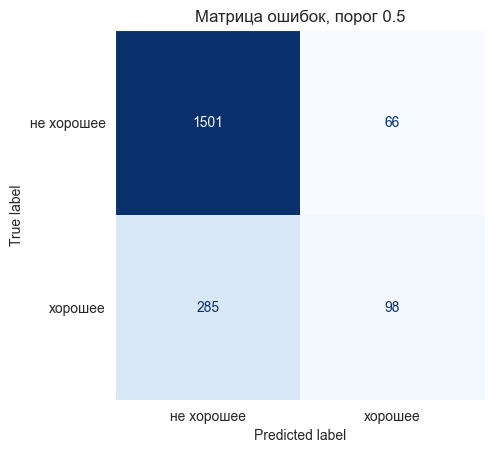

In [32]:
y_true = y_test.to_numpy()
y_pred = pipe.predict(X_test)

TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))
print(f'TP = {TP}, TN = {TN}, FP = {FP}, FN = {FN}')

cm = metrics.confusion_matrix(y_true, y_pred)
print(cm)
assert (cm == np.array([[TN, FP], [FN, TP]])).all()

metrics.ConfusionMatrixDisplay(cm, display_labels=['не хорошее', 'хорошее']).plot(cmap='Blues', colorbar=False)
plt.grid(False)
plt.title('Матрица ошибок, порог 0.5')
plt.show()

TP = 98, TN = 1501, FP = 66, FN = 285, совпадает с `confusion_matrix`.

- **FP:** посредственное вино попало в подборку, клиент разочарован.
- **FN:** хорошее вино не попало в подборку, подборка стала беднее.

Чаще модель ошибается с FN: 285 против 66, примерно в 4.3 раза. При пороге 0.5 она слишком осторожна и пропускает 285 из 383 хороших вин, то есть около 74%.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [33]:
def f_beta(precision, recall, beta):
    return (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall)


precision = TP / (TP + FP)
recall = TP / (TP + FN)

check = pd.DataFrame({
    'по формулам': [precision, recall, f_beta(precision, recall, 1),
                    f_beta(precision, recall, 0.5), f_beta(precision, recall, 2)],
    'sklearn': [metrics.precision_score(y_true, y_pred), metrics.recall_score(y_true, y_pred),
                metrics.fbeta_score(y_true, y_pred, beta=1),
                metrics.fbeta_score(y_true, y_pred, beta=0.5),
                metrics.fbeta_score(y_true, y_pred, beta=2)],
}, index=['precision', 'recall', 'F1', 'F0.5', 'F2'])
display(check.round(4))
assert np.allclose(check['по формулам'], check['sklearn'])

,по формулам,sklearn
precision,0.5976,0.5976
recall,0.2559,0.2559
F1,0.3583,0.3583
F0.5,0.4716,0.4716
F2,0.2889,0.2889


Значения по формулам совпали с `sklearn`: precision 0.5976, recall 0.2559, F1 0.3583, F0.5 0.4716, F2 0.2889.

В $F_{0.5}$ больше ценится precision, а в $F_2$ recall. Поэтому у нашей модели с высоким precision и низким recall $F_{0.5}$ выше, чем $F_2$.

Если подписчики болезненно реагируют на посредственные вина, важнее не допускать FP, тогда выбираем $F_{0.5}$. Если сервис обещает самую широкую подборку хороших вин, важнее не допускать FN, тогда подходит $F_2$.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

минимум log-loss на train (sklearn, C=inf): 0.391714


/Users/egorkuryukin/develop/coding/.conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


eta=0.01: итераций 4293, остановка по tolerance: True, loss = 0.395142
eta=0.1: итераций 5323, остановка по tolerance: True, loss = 0.391944
eta=1: итераций 1601, остановка по tolerance: True, loss = 0.391716
eta=3: итераций 705, остановка по tolerance: True, loss = 0.391714


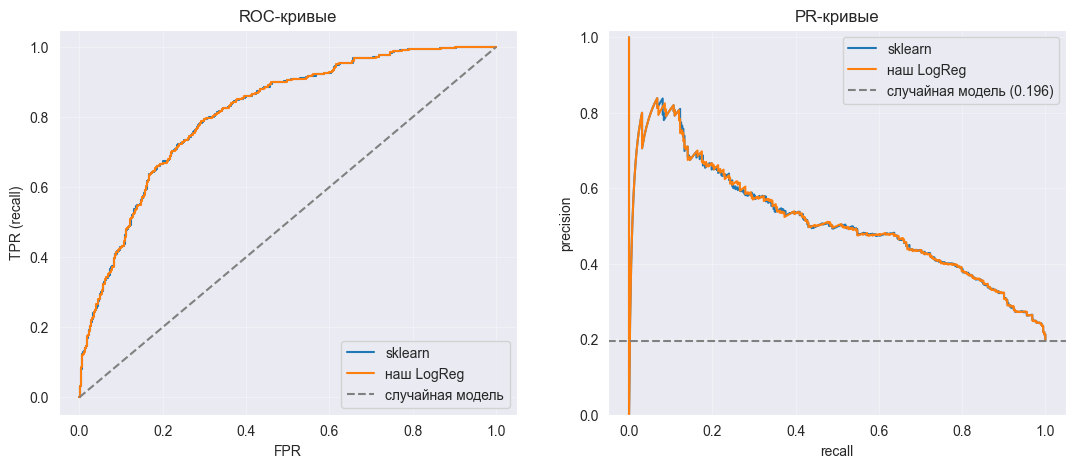

,ROC-AUC,PR-AUC
sklearn,0.81354,0.51211
наш LogReg,0.81352,0.51228


ROC-AUC для p: 0.813537
ROC-AUC для 10p: 0.813537
ROC-AUC для p^3: 0.813537
ROC-AUC для log(p / (1 - p)): 0.813537
ROC-AUC для -p: 0.186463
ROC-AUC по меткам классов: 0.6069
balanced accuracy: 0.6069


In [34]:
sk_exact = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=10000)).fit(X_train, y_train)
p_exact = np.clip(sk_exact.predict_proba(X_train)[:, 1], 1e-15, 1 - 1e-15)
print('минимум log-loss на train (sklearn, C=inf):', round(metrics.log_loss(y_train, p_exact), 6))

for eta in [0.01, 0.1, 1, 3]:
    candidate = make_pipeline(StandardScaler(), LogReg(eta=eta, max_iter=20000)).fit(X_train, y_train)
    log_reg = candidate[-1]
    print(f'eta={eta}: итераций {log_reg.n_iter_}, остановка по tolerance: {log_reg.stopped_by_tolerance_}, '
          f'loss = {log_reg.loss_history[-1]:.6f}')

own_pipe = make_pipeline(StandardScaler(), LogReg(eta=3, max_iter=20000)).fit(X_train, y_train)

scores = {'sklearn': pipe.predict_proba(X_test)[:, 1],
          'наш LogReg': own_pipe.predict_proba(X_test)[:, 1]}
prevalence = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, score in scores.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, score)
    prec, rec, _ = metrics.precision_recall_curve(y_test, score)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(rec, prec, label=name)

axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', label='случайная модель')
axes[0].set(xlabel='FPR', ylabel='TPR (recall)', title='ROC-кривые')
axes[1].axhline(prevalence, color='gray', linestyle='--',
                label=f'случайная модель ({prevalence:.3f})')
axes[1].set(xlabel='recall', ylabel='precision', title='PR-кривые', ylim=(0, 1.02))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

display(pd.DataFrame({name: {'ROC-AUC': metrics.roc_auc_score(y_test, score),
                             'PR-AUC': metrics.average_precision_score(y_test, score)}
                      for name, score in scores.items()}).T.round(5))

p = scores['sklearn']
transformed = {'p': p, '10p': 10 * p, 'p^3': p ** 3, 'log(p / (1 - p))': np.log(p / (1 - p)), '-p': -p}
for name, score in transformed.items():
    print(f'ROC-AUC для {name}: {metrics.roc_auc_score(y_test, score):.6f}')

label_auc = metrics.roc_auc_score(y_test, y_pred)
print('ROC-AUC по меткам классов:', round(label_auc, 4))
print('balanced accuracy:', round(metrics.balanced_accuracy_score(y_test, y_pred), 4))

Параметры спуска подбирал только по train. Минимум log-loss на train равен 0.391714 (sklearn с `C=inf`). С `eta=0.01` спуск остановился рано на 0.395142: при маленьком шаге разность весов становится меньше `tolerance` задолго до минимума. С `eta=0.1` получилось 0.391944, с `eta=1` 0.391716, а с `eta=3` 0.391714 за 705 итераций, то есть как раз минимум. Поэтому взял `eta=3`, `max_iter=20000`.

Модели практически одинаковые, их кривые на графиках накладываются: ROC-AUC 0.81354 у sklearn и 0.81352 у нашей, PR-AUC 0.51211 и 0.51228. По ROC-AUC чуть впереди sklearn, а по PR-AUC наша модель, то есть ранжирование формально разное. Но разница только в четвёртом-пятом знаке, это шум от слабой регуляризации в sklearn, поэтому считаю, что лучшей из них нет.

Для $10p$, $p^3$ и $\log\frac{p}{1-p}$ ROC-AUC тот же 0.813537, а для $-p$ получается 0.186463 = 1 - 0.813537. ROC-AUC зависит только от порядка объектов: это вероятность того, что случайный объект класса 1 получит оценку выше, чем случайный объект класса 0. Монотонно возрастающие преобразования порядок не меняют, а $-p$ разворачивает его.

PR-AUC случайной модели равен доле класса 1, здесь 0.196. Случайная модель при любом пороге отбирает вина независимо от класса, поэтому среди отобранных доля хороших такая же, как во всей выборке. Значение 0.5 было бы только при равных классах. Значит, наш PR-AUC 0.512 надо сравнивать с 0.196, а не с 0.5.

Ошибки у меток классов в `roc_auc_score` не будет, но получится 0.6069 вместо 0.8135. У меток всего два значения, поэтому кривая строится по одной точке и площадь равна (TPR + TNR) / 2, то есть balanced accuracy, она здесь тоже 0.6069. Это качество при одном пороге 0.5, а не качество ранжирования.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

хороших вин на валидации: 224 , на тесте: 383
t_F1 = 0.2689: на валидации F1 = 0.5455
t_R = 0.2432: на валидации precision = 0.4385, recall = 0.7009


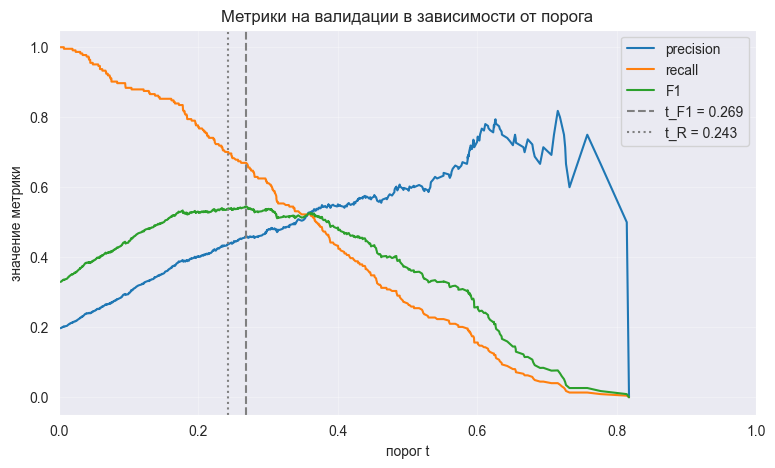

,t,precision,recall,F1
порог,,,,
0.5,0.5000,0.5976,0.2559,0.3583
t_F1,0.2689,0.4739,0.6397,0.5444
t_R,0.2432,0.4370,0.6789,0.5317


In [35]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)

val_pipe = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
val_proba = val_pipe.predict_proba(X_val)[:, 1]

val_precision, val_recall, thresholds = metrics.precision_recall_curve(y_val, val_proba)
val_precision, val_recall = val_precision[:-1], val_recall[:-1]
val_f1 = 2 * val_precision * val_recall / np.maximum(val_precision + val_recall, 1e-12)

t_f1 = thresholds[np.argmax(val_f1)]

candidates = np.where(val_recall >= 0.7)[0]
best_r = candidates[np.argmax(val_precision[candidates])]
t_r = thresholds[best_r]

print('хороших вин на валидации:', y_val.sum(), ', на тесте:', y_test.sum())
print(f't_F1 = {t_f1:.4f}: на валидации F1 = {val_f1.max():.4f}')
print(f't_R = {t_r:.4f}: на валидации precision = {val_precision[best_r]:.4f}, recall = {val_recall[best_r]:.4f}')

plt.figure(figsize=(9, 5))
plt.plot(thresholds, val_precision, label='precision')
plt.plot(thresholds, val_recall, label='recall')
plt.plot(thresholds, val_f1, label='F1')
plt.axvline(t_f1, color='gray', linestyle='--', label=f't_F1 = {t_f1:.3f}')
plt.axvline(t_r, color='gray', linestyle=':', label=f't_R = {t_r:.3f}')
plt.xlim(0, 1)
plt.xlabel('порог t')
plt.ylabel('значение метрики')
plt.title('Метрики на валидации в зависимости от порога')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

test_proba = pipe.predict_proba(X_test)[:, 1]

rows = []
for name, t in [('0.5', 0.5), ('t_F1', t_f1), ('t_R', t_r)]:
    pred = (test_proba >= t).astype(int)
    rows.append({'порог': name, 't': t,
                 'precision': metrics.precision_score(y_test, pred),
                 'recall': metrics.recall_score(y_test, pred),
                 'F1': metrics.f1_score(y_test, pred)})
display(pd.DataFrame(rows).set_index('порог').round(4))

На валидации получились $t_{F_1}$ = 0.2689 (F1 = 0.5455) и $t_R$ = 0.2432.

На тесте условие не выполнилось: при $t_R$ recall равен 0.6789, это меньше 0.7.

Порог подобран по конечной выборке, поэтому recall на новых данных случайно отличается от валидационного. На валидации всего 224 хороших вина, одно вино меняет recall примерно на 0.45 процентного пункта, а стандартная ошибка доли около 0.7 здесь примерно 0.03. На тесте хороших вин 383, и там своя случайность того же порядка. Отклонение на 0.02 вполне в этих пределах. К тому же $t_R$ стоит ровно на границе условия, без запаса, а итоговая модель обучена на большей выборке, чем та, для которой подбирался порогю

Для сценария я выбрал бы $t_{F_1}$ = 0.2689. В описании важны оба вида ошибок, и F1 как раз учитывает их вместе. Порог 0.5 не подходит: precision 0.5976, но модель теряет почти три четверти хороших вин (recall 0.2559). По сравнению с ним $t_{F_1}$ на тесте даёт recall 0.6397 при precision 0.4739 и F1 0.5444. Порог $t_R$ добавляет к recall 0.04 и столько же отнимает у precision, поэтому F1 у него ниже (0.5317). На графике видно, что F1 на валидации образует широкое плато примерно от 0.2 до 0.36, так что точное значение порога не критично.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [36]:
def eval_model(name, model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {'модель': name,
            'accuracy': metrics.accuracy_score(y, pred),
            'precision': metrics.precision_score(y, pred),
            'recall': metrics.recall_score(y, pred),
            'F1': metrics.f1_score(y, pred),
            'ROC-AUC': metrics.roc_auc_score(y, proba),
            'PR-AUC': metrics.average_precision_score(y, proba)}


def make_table(rows):
    return pd.DataFrame(rows).set_index('модель').round(4)


plain_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight=None)).fit(X_train, y_train)
balanced_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')).fit(X_train, y_train)

table_rows = [eval_model('без весов', plain_model, X_test, y_test),
              eval_model('class_weight=balanced', balanced_model, X_test, y_test)]
display(make_table(table_rows))

n_samples = len(y_train)
counts = np.bincount(y_train)
class_weights = n_samples / (2 * counts)
print('объектов в классах 0 и 1:', counts)
print(f'вес класса 0 = {class_weights[0]:.4f}, вес класса 1 = {class_weights[1]:.4f}')
print(f'отношение весов = {class_weights[1] / class_weights[0]:.2f}')

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
модель,,,,,,
без весов,0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
class_weight=balanced,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005


объектов в классах 0 и 1: [3653  894]
вес класса 0 = 0.6224, вес класса 1 = 2.5431
отношение весов = 4.09


В train 3653 объекта класса 0 и 894 объекта класса 1, поэтому вес класса 0 равен 4547 / (2 * 3653) = 0.6224, а вес класса 1 равен 4547 / (2 * 894) = 2.5431. Отношение весов 4.09, оно равно соотношению классов (на самом деле класс 1 реже примерно в 4 раза).

Заметно изменились метрики, зависящие от порога: recall вырос с 0.2559 до 0.7546, precision упал с 0.5976 до 0.3970, F1 вырос с 0.3583 до 0.5203, accuracy упала с 0.82 до 0.7267. Почти не изменились ROC-AUC (0.8135 и 0.8113) и PR-AUC (0.5121 и 0.5005).

Веса делают ошибку на редком классе дороже, и модель поднимает вероятности класса 1. При том же пороге 0.5 в класс 1 попадает гораздо больше объектов: хороших вин находится больше, но растёт и FP, поэтому падают precision и accuracy. Порядок объектов при этом почти не меняется, в основном сдвигается свободный член (проверено в 3.3), а ROC-AUC и PR-AUC от порога не зависят.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [37]:
from imblearn.pipeline import make_pipeline as imb_make_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
            'NearMiss-2': NearMiss(version=2),
            'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
            'SMOTE': SMOTE(random_state=RANDOM_STATE)}

X_train_scaled = StandardScaler().fit_transform(X_train)
resampled_models = {}

for name, sampler in samplers.items():
    _, y_resampled = sampler.fit_resample(X_train_scaled, y_train)
    print(f'{name}: класс 0 = {(y_resampled == 0).sum()}, класс 1 = {(y_resampled == 1).sum()}')

    model = imb_make_pipeline(StandardScaler(), sampler, LogisticRegression())
    model.fit(X_train, y_train)
    resampled_models[name] = model
    table_rows.append(eval_model(name, model, X_test, y_test))

display(make_table(table_rows))

order_rows = []
for name, sampler in samplers.items():
    scaled_first = resampled_models[name]
    sampled_first = imb_make_pipeline(sampler, StandardScaler(), LogisticRegression()).fit(X_train, y_train)
    order_rows.append(eval_model(f'{name}: scaler -> sampler', scaled_first, X_test, y_test))
    order_rows.append(eval_model(f'{name}: sampler -> scaler', sampled_first, X_test, y_test))
display(make_table(order_rows))

RandomUnderSampler: класс 0 = 894, класс 1 = 894
NearMiss-2: класс 0 = 894, класс 1 = 894
RandomOverSampler: класс 0 = 3653, класс 1 = 3653
SMOTE: класс 0 = 3653, класс 1 = 3653


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
модель,,,,,,
без весов,0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
class_weight=balanced,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
RandomUnderSampler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
NearMiss-2,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
RandomOverSampler,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
SMOTE,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
модель,,,,,,
RandomUnderSampler: scaler -> sampler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
RandomUnderSampler: sampler -> scaler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5005
NearMiss-2: scaler -> sampler,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
NearMiss-2: sampler -> scaler,0.6810,0.3512,0.7363,0.4755,0.7550,0.3934
RandomOverSampler: scaler -> sampler,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
RandomOverSampler: sampler -> scaler,0.7262,0.3964,0.7546,0.5198,0.8115,0.5003
SMOTE: scaler -> sampler,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040
SMOTE: sampler -> scaler,0.7338,0.4042,0.7493,0.5252,0.8116,0.5090


После ресемплинга в обучающей выборке по 894 объекта каждого класса у `RandomUnderSampler` и `NearMiss-2` и по 3653 у `RandomOverSampler` и `SMOTE`.

`make_pipeline` нужен из `imblearn`, потому что у сэмплеров нет метода `transform`, только `fit_resample`, и пайплайн `sklearn` с ними не работает. Пайплайн `imblearn` делает ресемплинг только при `fit`, а при `predict` этот шаг пропускается, так что тестовая выборка не меняется.

Балансировать до разбиения нельзя: копии и синтетические объекты попадут и в train, и в test, получится утечка. К тому же доля класса 1 в тесте станет 0.5 вместо 0.196, и precision с PR-AUC перестанут показывать качество на реальных данных.

По PR-AUC лучший SMOTE (0.5040), худший NearMiss-2 (0.4001). SMOTE, `RandomUnderSampler` и `RandomOverSampler` отличаются только в третьем знаке, и ни один не обогнал модель без балансировки (0.5121): порядок объектов у логистической регрессии почти не меняется, сдвигается в основном порог. NearMiss-2 оставляет из класса 0 только объекты, ближайшие к самым далёким объектам класса 1, то есть нетипичные. Поэтому у него самый высокий recall (0.8538), но самые низкие precision (0.2819) и ROC-AUC (0.7399).

Порядок масштабирования и ресемплинга важен для NearMiss и SMOTE, потому что они ищут ближайших соседей, а без масштабирования расстояние почти целиком задаёт `total_sulfur_dioxide` (значения до 440). Случайным методам масштаб не важен. Это видно во второй таблице: у `RandomUnderSampler` и `RandomOverSampler` метрики почти не меняются (разница не больше 0.003), а у NearMiss-2 accuracy меняется с 0.5441 до 0.6810, у SMOTE PR-AUC с 0.5040 до 0.5090. Без масштабирования вышло даже чуть лучше, но выбирать порядок по тесту нельзя, поэтому масштабирование оставил первым.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

class_weight=balanced, порог 0.5: precision = 0.3970, recall = 0.7546, F1 = 0.5203
без весов, порог t_F1 = 0.269: precision = 0.4739, recall = 0.6397, F1 = 0.5444


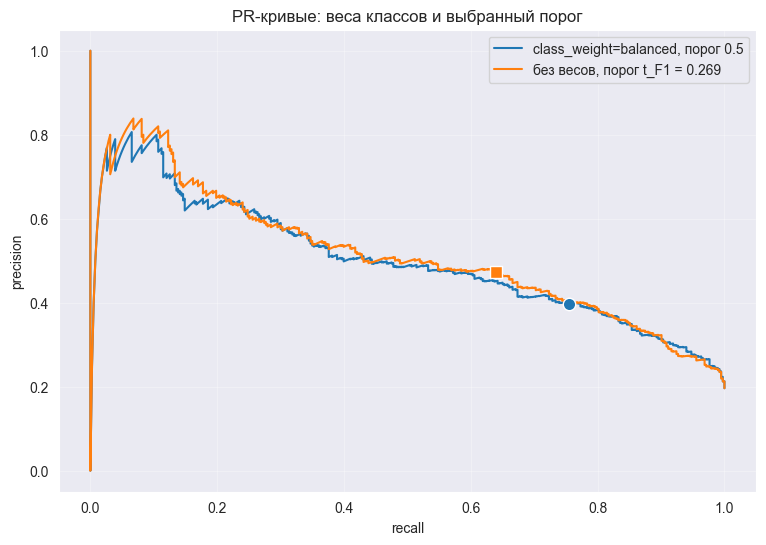

PR-AUC: с весами 0.5005 , без весов 0.5121
без весов с порогом 0.197 и с весами с порогом 0.5: совпадает 97.6% меток
сдвиг свободного члена: 1.367 , log(n0 / n1): 1.408
max |разность коэффициентов|: 0.177


In [38]:
weighted_proba = balanced_model.predict_proba(X_test)[:, 1]
plain_proba = plain_model.predict_proba(X_test)[:, 1]

curves = {'class_weight=balanced, порог 0.5': (weighted_proba, 0.5),
          f'без весов, порог t_F1 = {t_f1:.3f}': (plain_proba, t_f1)}

plt.figure(figsize=(9, 6))
for (name, (proba, t)), marker in zip(curves.items(), ['o', 's']):
    prec, rec, _ = metrics.precision_recall_curve(y_test, proba)
    line, = plt.plot(rec, prec, label=name)
    pred = (proba >= t).astype(int)
    point = (metrics.recall_score(y_test, pred), metrics.precision_score(y_test, pred))
    plt.scatter(*point, color=line.get_color(), marker=marker, s=80, zorder=3, edgecolor='white')
    print(f'{name}: precision = {point[1]:.4f}, recall = {point[0]:.4f}, '
          f'F1 = {metrics.f1_score(y_test, pred):.4f}')
plt.xlabel('recall')
plt.ylabel('precision')
plt.title('PR-кривые: веса классов и выбранный порог')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('PR-AUC: с весами', round(metrics.average_precision_score(y_test, weighted_proba), 4),
      ', без весов', round(metrics.average_precision_score(y_test, plain_proba), 4))

t_prior = y_train.mean()
same_labels = ((plain_proba >= t_prior) == (weighted_proba >= 0.5)).mean()
print(f'без весов с порогом {t_prior:.3f} и с весами с порогом 0.5: совпадает {same_labels:.1%} меток')

w_plain = plain_model[-1]
w_balanced = balanced_model[-1]
print('сдвиг свободного члена:', round((w_balanced.intercept_ - w_plain.intercept_)[0], 3),
      ', log(n0 / n1):', round(np.log(counts[0] / counts[1]), 3))
print('max |разность коэффициентов|:', round(np.abs(w_balanced.coef_ - w_plain.coef_).max(), 3))

Кривые различаются слабо: заметно только в начале при recall меньше 0.15, дальше они почти совпадают. PR-AUC 0.5005 с весами и 0.5121 без весов. Две отмеченные точки лежат почти на одной кривой, просто в разных местах: с весами precision 0.3970 и recall 0.7546, без весов с порогом $t_{F_1}$ precision 0.4739 и recall 0.6397. F1 у модели с порогом выше (0.5444 против 0.5203).

Да, взвешивание классов в основном сдвигает порог. Вес класса 1 сдвигает логит на $\log(n_0 / n_1)$ = 1.408, и фактический сдвиг свободного члена близок к этому (1.367). Сдвиг логита на эту величину равен выбору порога $n_1 / (n_0 + n_1)$ = 0.197 у модели без весов. Если взять такой порог, совпадает 97.6% предсказанных меток с моделью с весами. Коэффициенты при этом меняются немного, не больше чем на 0.177, поэтому кривые и получаются близкими.

Значит, тот же результат можно получить без переобучения, подбирая порог.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [39]:
final_table = make_table([
    eval_model('LogReg sklearn, порог 0.5', pipe, X_test, y_test),
    eval_model('LogReg sklearn, порог t_F1', pipe, X_test, y_test, threshold=t_f1),
    eval_model('LogReg sklearn, порог t_R', pipe, X_test, y_test, threshold=t_r),
    eval_model('наш LogReg, порог 0.5', own_pipe, X_test, y_test),
    *table_rows[1:],
])
final_table

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
модель,,,,,,
"LogReg sklearn, порог 0.5",0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
"LogReg sklearn, порог t_F1",0.7897,0.4739,0.6397,0.5444,0.8135,0.5121
"LogReg sklearn, порог t_R",0.7651,0.4370,0.6789,0.5317,0.8135,0.5121
"наш LogReg, порог 0.5",0.8221,0.6071,0.2663,0.3702,0.8135,0.5123
class_weight=balanced,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
RandomUnderSampler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
NearMiss-2,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
RandomOverSampler,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
SMOTE,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040


Итог: как будто для сервиса подходит обычная логистическая регрессия из `sklearn` без весов и ресемплинга с порогом $t_{F_1}$ = 0.2689.

- У неё лучший F1 в таблице, 0.5444. Лучшая из моделей с балансировкой (`RandomUnderSampler`) даёт 0.5257.
- Лучшие ROC-AUC (0.8135) и почти лучший PR-AUC (0.5121, наш LogReg 0.5123), то есть балансировка качество ранжирования не улучшила.
- При таком пороге precision 0.4739 и recall 0.6397: в подборку попадает почти две трети хороших вин, а хорошим оказывается примерно каждое второе вино из подборки. Для сценария, где важны оба вида ошибок, это разумный баланс.
- Модель самая простая: не нужен шаг ресемплинга, а вероятности не искажены весами. Порог можно менять под требования сервиса без переобучения, что как раз и позволяет приложение из части 4.

Порог выбран на валидации, а модель определена заранее, поэтому тест здесь используется только для итоговой оценки. Если сервису принципиально важно отбирать не меньше 70% хороших вин, порог нужно опустить ниже $t_R$, с запасом, потому что на тесте при $t_R$ recall оказался 0.6789. Precision при этом снизится примерно до уровня моделей с балансировкой (около 0.40).

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [40]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = pipe      # ваш итоговый пайплайн, обученный на X_train
final_threshold = t_f1  # выбранный порог

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

- Github: https://github.com/Egorixa/mmad26-hw3-streamlit
- Streamlit: https://6pz5nqe8ny3nh8ioacbrb2.streamlit.app/

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷